<a href="https://colab.research.google.com/github/iles-mcgill/EXSU500-Paediatric-HGGs-AI/blob/baseline-rf/notebooks/03_baseline_and_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
257 patients
Counter({'seg.nii.gz': 257, 't1n.nii.gz': 257, 't1c.nii.gz': 257, 't2f.nii.gz': 257, 't2w.nii.gz': 257})
Scan size: (240, 240, 155) | voxel size (mm): (1.0, 1.0, 1.0)
Label numbers in the mask: [0 1 2 3 4]


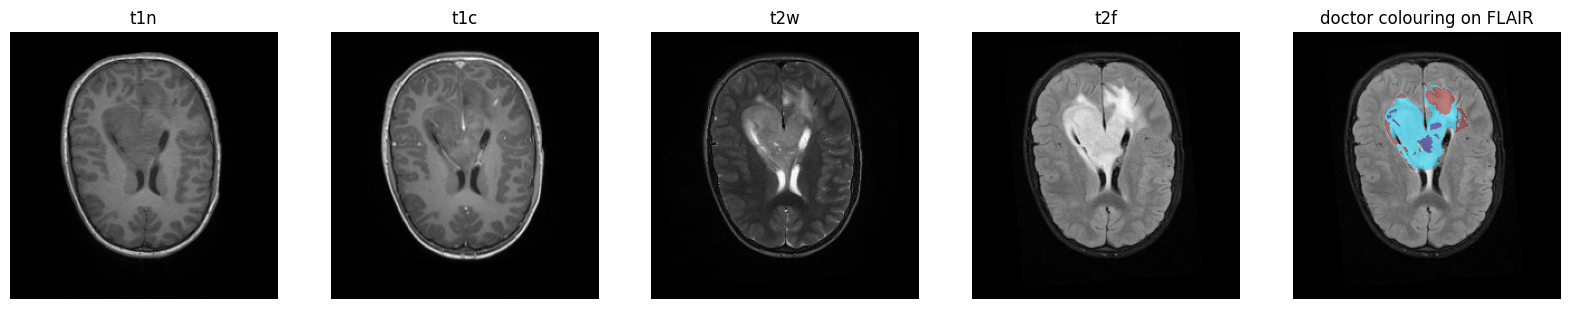

In [ ]:
# CELL 1: setup, check the data, look at one patient
from google.colab import drive
drive.mount('/content/drive')

!pip install -q nibabel
import os, glob, json, random
from collections import Counter
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import joblib
from scipy import ndimage

DATA_DIR = '/content/drive/MyDrive/BraTS-PEDs-full/Training'

def find_file(case_dir, key):
    # find the one file in a patient's folder whose name contains key, e.g. 't2f' or 'seg'
    hits = glob.glob(os.path.join(case_dir, f'*{key}*.nii*'))
    if len(hits) != 1:
        raise FileNotFoundError(f'Expected 1 file containing {key} in {case_dir}, found {len(hits)}')
    return hits[0]

def load_case(case_dir):
    # load one patient's 4 scans and the doctor's mask
    seqs = {}
    for key in ['t1n', 't1c', 't2w', 't2f']:
        seqs[key] = nib.load(find_file(case_dir, key)).get_fdata(dtype=np.float32)
    seg_img = nib.load(find_file(case_dir, 'seg'))
    seg = np.rint(np.asarray(seg_img.dataobj)).astype(np.uint8)
    spacing = tuple(float(s) for s in seg_img.header.get_zooms()[:3])
    return seqs, seg, spacing

# check the dataset is complete
patients = sorted(p for p in os.listdir(DATA_DIR) if p.startswith('BraTS'))
all_files = glob.glob(os.path.join(DATA_DIR, '*', '*.nii*'))
print(len(patients), 'patients')
print(Counter(f.split('-')[-1] for f in all_files))   # want 257 of each

# look at one patient
seqs, seg, spacing = load_case(os.path.join(DATA_DIR, patients[0]))
print('Scan size:', seqs['t2f'].shape, '| voxel size (mm):', spacing)
print('Label numbers in the mask:', np.unique(seg))
z = int(np.argmax((seg > 0).sum(axis=(0, 1))))
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, key in zip(axes[:4], ['t1n', 't1c', 't2w', 't2f']):
    ax.imshow(np.rot90(seqs[key][:, :, z]), cmap='gray')
    ax.set_title(key)
    ax.axis('off')
axes[4].imshow(np.rot90(seqs['t2f'][:, :, z]), cmap='gray')
mask = np.ma.masked_where(seg[:, :, z] == 0, seg[:, :, z])
axes[4].imshow(np.rot90(mask), cmap='jet', alpha=0.5, vmin=1, vmax=4)
axes[4].set_title('doctor colouring on FLAIR')
axes[4].axis('off')
plt.show()

In [ ]:
# CELL 2: scoring code (Dice and HD95) and tests
MAX_HD95 = 373.13   # BraTS maximum penalty: the diagonal of a 240 x 240 x 155 mm volume

def region_masks(seg):
    # turn a label map (0-4) into the regions we score
    return {
        'WT': seg > 0,                    # whole tumour = all labels
        'TC': np.isin(seg, [1, 2, 3]),    # tumour core = everything except swelling
        'ET': seg == 1, 'NET': seg == 2, 'CC': seg == 3, 'ED': seg == 4,
    }

def dice(pred, ref):
    pred, ref = pred.astype(bool), ref.astype(bool)
    if not pred.any() and not ref.any():
        return 1.0                        # BraTS rule: both empty = correct
    return 2.0 * np.logical_and(pred, ref).sum() / (pred.sum() + ref.sum())

def surface(mask):
    # the outer layer of voxels of a shape
    return mask & ~ndimage.binary_erosion(mask)

def hd95(pred, ref, spacing=(1.0, 1.0, 1.0)):
    pred, ref = pred.astype(bool), ref.astype(bool)
    if not pred.any() and not ref.any():
        return 0.0                        # BraTS rule: both empty = correct
    if not pred.any() or not ref.any():
        return MAX_HD95                   # BraTS rule: one empty = maximum penalty
    sp, sr = surface(pred), surface(ref)
    dist_to_ref = ndimage.distance_transform_edt(~sr, sampling=spacing)
    dist_to_pred = ndimage.distance_transform_edt(~sp, sampling=spacing)
    distances = np.concatenate([dist_to_ref[sp], dist_to_pred[sr]])
    return float(np.percentile(distances, 95))

def score_case(pred_seg, ref_seg, spacing, regions=None):
    # score one patient; regions=None means all six regions
    p, r = region_masks(pred_seg), region_masks(ref_seg)
    out = {'ref_volume_WT_cm3': float(r['WT'].sum() * np.prod(spacing) / 1000)}
    for name in (regions or list(r)):
        out[f'dice_{name}'] = dice(p[name], r[name])
        out[f'hd95_{name}'] = hd95(p[name], r[name], spacing)
        out[f'present_{name}'] = bool(r[name].any())
    return out

# TEST 1: fake shapes
a = np.zeros((10, 10, 10), bool); a[2:5, 2:5, 2:5] = True    # a small cube
b = np.zeros((10, 10, 10), bool)                              # nothing
c = np.zeros((10, 10, 10), bool); c[3:6, 2:5, 2:5] = True    # the cube moved by 1 voxel
print(dice(a, a), hd95(a, a))    # should print: 1.0 0.0
print(dice(b, b), hd95(b, b))    # should print: 1.0 0.0
print(dice(a, b), hd95(a, b))    # should print: 0.0 373.13
print(round(dice(a, c), 3))      # should print: 0.667

# TEST 2: the doctor's colouring compared with itself must be perfect
print(score_case(seg, seg, spacing))   # every dice_ = 1.0, every hd95_ = 0.0

1.0 0.0
1.0 0.0
0.0 373.13
0.667
{'ref_volume_WT_cm3': 128.667, 'dice_WT': np.float64(1.0), 'hd95_WT': 0.0, 'present_WT': True, 'dice_TC': np.float64(1.0), 'hd95_TC': 0.0, 'present_TC': True, 'dice_ET': np.float64(1.0), 'hd95_ET': 0.0, 'present_ET': True, 'dice_NET': np.float64(1.0), 'hd95_NET': 0.0, 'present_NET': True, 'dice_CC': np.float64(1.0), 'hd95_CC': 0.0, 'present_CC': True, 'dice_ED': np.float64(1.0), 'hd95_ED': 0.0, 'present_ED': True}
